In [1]:
from google.colab import files

In [5]:
uploaded = files.upload()

Saving student+performance.zip to student+performance (1).zip


In [6]:
import zipfile
import os

zip_name = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("student_data")

print(os.listdir("student_data"))

['.student.zip_old', 'student.zip']


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "student__data/student-por.csv",
    sep=","
)

print(df.shape)
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'student__data/student-por.csv'

In [8]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: /content
Files here: ['.config', 'student_data', 'student+performance.zip', 'student+performance (1).zip', 'sample_data']


In [9]:
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [10]:
import zipfile
import os

with zipfile.ZipFile("/content/student+performance.zip", "r") as z:
    print(z.namelist())

['.student.zip_old', 'student.zip']


In [11]:
with zipfile.ZipFile("/content/student+performance.zip", "r") as z:
    z.extractall("/content/student_data")

print(os.listdir("/content/student_data"))

['.student.zip_old', 'student.zip']


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/student_data/student-por.csv", sep=";")

print("Shape:", df.shape)
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/student_data/student-por.csv'

In [13]:
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the CSV inside either ZIP file
df = None

for filename in os.listdir("/content"):
    if filename.lower().endswith(".zip"):
        try:
            with zipfile.ZipFile(os.path.join("/content", filename)) as z:
                matches = [
                    name for name in z.namelist()
                    if name.lower().endswith("student-por.csv")
                ]

                if matches:
                    with z.open(matches[0]) as f:
                        df = pd.read_csv(f, sep=";")
                    print("Loaded from:", filename)
                    break
        except zipfile.BadZipFile:
            continue

if df is not None:
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("CSV not found. ZIP contents:")
    for filename in os.listdir("/content"):
        if filename.lower().endswith(".zip"):
            with zipfile.ZipFile(os.path.join("/content", filename)) as z:
                print(filename, z.namelist())

CSV not found. ZIP contents:
student+performance.zip ['.student.zip_old', 'student.zip']
student+performance (1).zip ['.student.zip_old', 'student.zip']


In [14]:
import zipfile
import pandas as pd

# Open the outer ZIP
with zipfile.ZipFile("/content/student+performance.zip") as outer:

    # Extract the inner ZIP into memory
    inner_zip = outer.read("student.zip")

    # Open the inner ZIP
    import io
    with zipfile.ZipFile(io.BytesIO(inner_zip)) as inner:

        print("Files inside inner ZIP:", inner.namelist())

        # Find and load the Portuguese dataset
        csv_file = next(
            name for name in inner.namelist()
            if name.endswith("student-por.csv")
        )

        with inner.open(csv_file) as f:
            df = pd.read_csv(f, sep=";")

print("Dataset shape:", df.shape)
display(df.head())

Files inside inner ZIP: ['student-mat.csv', 'student-por.csv', 'student-merge.R', 'student.txt']
Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [17]:
print(df.shape)

(649, 33)


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [21]:
df.isnull().sum()

,0
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


In [22]:
df[["studytime","absences","G1","G2","G3"]].head(10)

,studytime,absences,G1,G2,G3
0,2,4,0,11,11
1,2,2,9,11,11
2,2,6,12,13,12
3,3,0,14,14,14
4,2,0,11,13,13
5,2,6,12,12,13
6,2,0,13,12,13
7,2,2,10,13,13
8,2,0,15,16,17
9,2,0,12,12,13


In [23]:
df["G3"].describe()

,G3
count,649.000000
mean,11.906009
std,3.230656
min,0.000000
25%,10.000000
50%,12.000000
75%,14.000000
max,19.000000


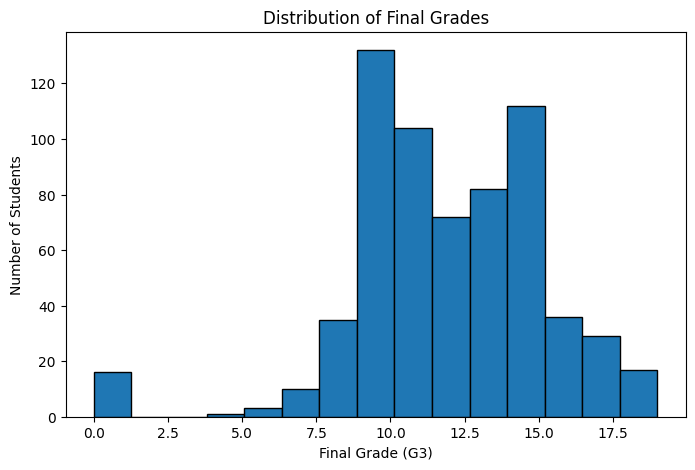

In [24]:
plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=15, edgecolor="black")

plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Grades")

plt.show()

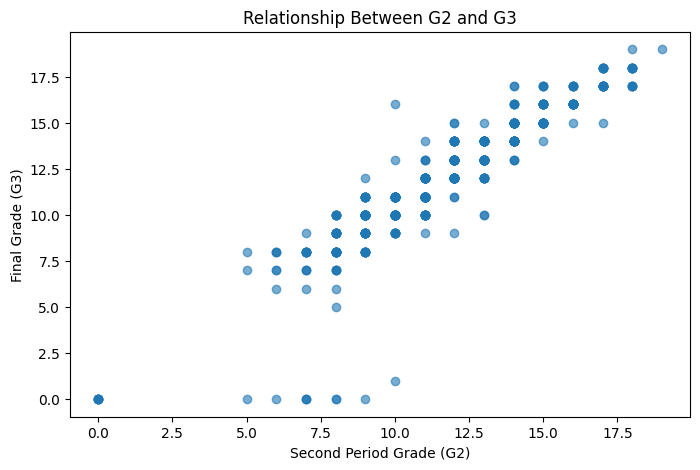

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(df["G2"], df["G3"], alpha=0.6)

plt.xlabel("Second Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("Relationship Between G2 and G3")

plt.show()

In [26]:
print("correlatio between G2 and G3:")
print(df["G2"].corr(df["G3"]))

correlatio between G2 and G3:
0.9185480035603504


In [27]:
X = df[["G2"]].to_numpy()
y = df["G3"].to_numpy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (649, 1)
y shape: (649,)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (519, 1)
X_test: (130, 1)
y_train: (519,)
y_test: (130,)


In [31]:
m = 0.0
b = 0.0

learning_rate = 0.001
epochs = 10000

n = len(X_train)

In [32]:
for i in range(epochs):

    y_pred = m * X_train.ravel() + b

    dm = (-2 / n) * np.sum(
        X_train.ravel() * (y_train - y_pred)
    )

    db = (-2 / n) * np.sum(y_train - y_pred)


    m = m - learning_rate * dm
    b = b - learning_rate * db

print("Slope:", m)
print("Intercept:", b)

Slope: 1.0285304519144007
Intercept: 0.010271768960193724


In [33]:
y_test_pred = m * X_test.ravel() + b

In [34]:
for i in range(10):
    print("Actual:", y_test[i], "| Predicted:", y_test_pred[i])

Actual: 19 | Predicted: 18.523819903419408
Actual: 12 | Predicted: 11.324106740018603
Actual: 18 | Predicted: 18.523819903419408
Actual: 11 | Predicted: 11.324106740018603
Actual: 11 | Predicted: 11.324106740018603
Actual: 17 | Predicted: 16.466758999590606
Actual: 18 | Predicted: 17.495289451505005
Actual: 8 | Predicted: 9.267045836189801
Actual: 10 | Predicted: 10.295576288104202
Actual: 11 | Predicted: 10.295576288104202


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
print("R2 Score:", r2_score(y_test, y_test_pred))

MAE: 0.7289451508429515
MSE: 1.2765567125908768
RMSE: 1.1298480927057746
R2 Score: 0.8690941455135445


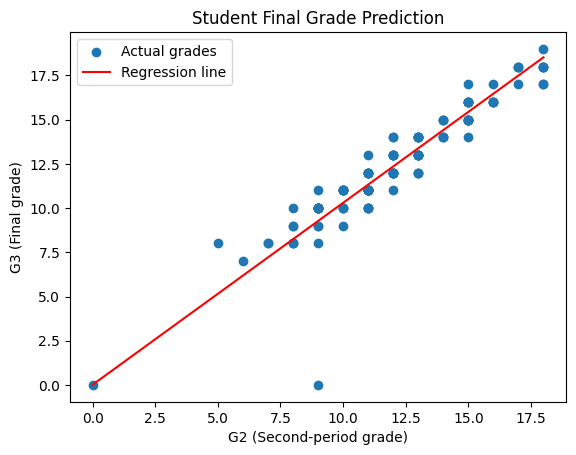

In [36]:
import numpy as np
import matplotlib.pyplot as plt

idx = np.argsort(X_test.ravel())

plt.scatter(X_test.ravel(), y_test, label="Actual grades")
plt.plot(X_test.ravel()[idx], y_test_pred[idx],
         color="red", label="Regression line")

plt.xlabel("G2 (Second-period grade)")
plt.ylabel("G3 (Final grade)")
plt.title("Student Final Grade Prediction")
plt.legend()
plt.show()

In [37]:
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))
print("R²:", r2_score(y_test, y_test_pred))

MAE: 0.7289451508429515
RMSE: 1.1298480927057746
R²: 0.8690941455135445
